# MLB Baseball Operations: Next-Season Pitcher Whiff Breakout Prediction

## Objective

Build a **pitcher-development forecasting model** that estimates:

> **Given a pitcher's arsenal and performance through season `t`, what is the probability that his overall whiff rate improves by at least 2 percentage points in season `t+1`?**

This is designed as a player-development / scouting question rather than a descriptive leaderboard.

### Primary target

For each pitcher-season, calculate an arsenal-weighted whiff rate:

\[
\text{Weighted Whiff Rate}
=
\frac{\sum_p \text{Usage}_p \times \text{Whiff Rate}_p}
{\sum_p \text{Usage}_p}
\]

Then define:

\[
\text{Whiff Breakout}_{t+1}
=
1\left(
\text{Weighted Whiff}_{t+1}
-
\text{Weighted Whiff}_{t}
\ge 0.02
\right)
\]

### Modeling design

- Observation unit: **one pitcher-season**
- Source: `pitcher_arsenal_evolution_2020_2025.csv`
- Training feature seasons: **2020–2022**
- Validation feature season: **2023 → 2024 outcome**
- Untouched test feature season: **2024 → 2025 outcome**
- Deployment population: **2025 → 2026 breakout probability**
- Models:
  - prevalence baseline
  - logistic regression
  - random forest
  - XGBoost
  - Bayesian hyperparameter optimization with Optuna
- Evaluation:
  - ROC-AUC
  - PR-AUC
  - log loss
  - Brier score
  - precision / recall / F1
  - calibration
  - feature importance

Because next-season whiff rate is undefined for pitchers who do not appear the following season, the historical target is evaluated **conditional on returning to MLB the next season**. The 2026 deployment board should therefore be interpreted as breakout probability *if the pitcher records pitches in MLB in 2026*.


In [1]:
# Core imports
from pathlib import Path
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)
from sklearn.calibration import calibration_curve

from xgboost import XGBClassifier
import optuna

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
N_TRIALS = int(os.getenv("OPTUNA_TRIALS", "20"))
BREAKOUT_THRESHOLD = 0.02

pd.set_option("display.max_columns", 160)
pd.set_option("display.width", 200)


## 1. Load the pitcher arsenal dataset

The file contains one pitcher-season per row and pitch-type-specific measurements for:

- usage percentage,
- average velocity,
- average spin rate,
- whiff rate,
- horizontal movement,
- vertical movement.

The columns cover up to 18 Statcast pitch classifications.


In [2]:
DATA_CANDIDATES = [
    Path("pitcher_arsenal_evolution_2020_2025.csv"),
    Path("/mnt/data/pitcher_arsenal_evolution_2020_2025.csv"),
]

DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find pitcher_arsenal_evolution_2020_2025.csv. "
        "Put it beside this notebook or update DATA_CANDIDATES."
    )

raw = pd.read_csv(DATA_PATH)

print("Loaded:", DATA_PATH)
print("Shape:", raw.shape)
print("Seasons:", int(raw["season"].min()), "to", int(raw["season"].max()))
print("Pitchers:", raw["player_id"].nunique())
display(raw.head())


Loaded: pitcher_arsenal_evolution_2020_2025.csv
Shape: (4253, 111)
Seasons: 2020 to 2025
Pitchers: 1458


,player_id,player_name,season,CH_usage_pct,CS_usage_pct,CU_usage_pct,EP_usage_pct,FA_usage_pct,FC_usage_pct,FF_usage_pct,FO_usage_pct,FS_usage_pct,KC_usage_pct,KN_usage_pct,PO_usage_pct,SC_usage_pct,SI_usage_pct,SL_usage_pct,ST_usage_pct,SV_usage_pct,UN_usage_pct,CH_avg_speed,CS_avg_speed,CU_avg_speed,EP_avg_speed,FA_avg_speed,FC_avg_speed,FF_avg_speed,FO_avg_speed,FS_avg_speed,KC_avg_speed,KN_avg_speed,PO_avg_speed,SC_avg_speed,SI_avg_speed,SL_avg_speed,ST_avg_speed,SV_avg_speed,UN_avg_speed,CH_avg_spin,CS_avg_spin,CU_avg_spin,EP_avg_spin,FA_avg_spin,FC_avg_spin,FF_avg_spin,FO_avg_spin,FS_avg_spin,KC_avg_spin,KN_avg_spin,PO_avg_spin,SC_avg_spin,SI_avg_spin,SL_avg_spin,ST_avg_spin,SV_avg_spin,UN_avg_spin,CH_whiff_rate,CS_whiff_rate,CU_whiff_rate,EP_whiff_rate,FA_whiff_rate,FC_whiff_rate,FF_whiff_rate,FO_whiff_rate,FS_whiff_rate,KC_whiff_rate,KN_whiff_rate,PO_whiff_rate,SC_whiff_rate,SI_whiff_rate,SL_whiff_rate,ST_whiff_rate,SV_whiff_rate,UN_whiff_rate,CH_avg_pfx_x,CS_avg_pfx_x,CU_avg_pfx_x,EP_avg_pfx_x,FA_avg_pfx_x,FC_avg_pfx_x,FF_avg_pfx_x,FO_avg_pfx_x,FS_avg_pfx_x,KC_avg_pfx_x,KN_avg_pfx_x,PO_avg_pfx_x,SC_avg_pfx_x,SI_avg_pfx_x,SL_avg_pfx_x,ST_avg_pfx_x,SV_avg_pfx_x,UN_avg_pfx_x,CH_avg_pfx_z,CS_avg_pfx_z,CU_avg_pfx_z,EP_avg_pfx_z,FA_avg_pfx_z,FC_avg_pfx_z,FF_avg_pfx_z,FO_avg_pfx_z,FS_avg_pfx_z,KC_avg_pfx_z,KN_avg_pfx_z,PO_avg_pfx_z,SC_avg_pfx_z,SI_avg_pfx_z,SL_avg_pfx_z,ST_avg_pfx_z,SV_avg_pfx_z,UN_avg_pfx_z
0,424144,óliver pérez,2020,NaN,NaN,NaN,NaN,NaN,NaN,13.64,NaN,NaN,NaN,NaN,NaN,NaN,43.01,43.36,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.52,NaN,NaN,NaN,NaN,NaN,NaN,89.94,76.05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2152.0,NaN,NaN,NaN,NaN,NaN,NaN,2102.0,2192.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0968,NaN,NaN,NaN,NaN,NaN,NaN,0.1000,0.1392,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.97,NaN,NaN,NaN,NaN,NaN,NaN,1.48,-0.82,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.29,NaN,NaN,NaN,NaN,NaN,NaN,0.62,-0.10,NaN,NaN,NaN
1,425794,adam wainwright,2020,2.40,NaN,38.42,NaN,NaN,21.86,9.88,NaN,NaN,NaN,NaN,NaN,NaN,27.45,NaN,NaN,NaN,NaN,81.84,NaN,73.56,NaN,NaN,85.04,89.12,NaN,NaN,NaN,NaN,NaN,NaN,89.37,NaN,NaN,NaN,NaN,1679.0,NaN,2788.0,NaN,NaN,2344.0,2222.0,NaN,NaN,NaN,NaN,NaN,NaN,2189.0,NaN,NaN,NaN,NaN,0.1000,NaN,0.2325,NaN,NaN,0.1699,0.0690,NaN,NaN,NaN,NaN,NaN,NaN,0.0647,NaN,NaN,NaN,NaN,-1.14,NaN,1.40,NaN,NaN,0.50,-0.17,NaN,NaN,NaN,NaN,NaN,NaN,-1.02,NaN,NaN,NaN,NaN,0.58,NaN,-1.18,NaN,NaN,0.51,1.20,NaN,NaN,NaN,NaN,NaN,NaN,0.95,NaN,NaN,NaN,NaN
2,425794,adam wainwright,2021,6.79,0.40,33.48,NaN,NaN,21.33,10.13,NaN,NaN,NaN,NaN,NaN,NaN,27.88,NaN,NaN,NaN,NaN,82.76,65.84,73.48,NaN,NaN,84.92,89.00,NaN,NaN,NaN,NaN,NaN,NaN,89.09,NaN,NaN,NaN,NaN,1729.0,2554.0,2837.0,NaN,NaN,2406.0,2232.0,NaN,NaN,NaN,NaN,NaN,NaN,2227.0,NaN,NaN,NaN,NaN,0.1203,0.3333,0.1793,NaN,NaN,0.1449,0.0753,NaN,NaN,NaN,NaN,NaN,NaN,0.0466,NaN,NaN,NaN,NaN,-1.15,1.25,1.38,NaN,NaN,0.53,-0.14,NaN,NaN,NaN,NaN,NaN,NaN,-1.06,NaN,NaN,NaN,NaN,0.64,-1.25,-1.22,NaN,NaN,0.53,1.22,NaN,NaN,NaN,NaN,NaN,NaN,1.02,NaN,NaN,NaN,NaN
3,425794,adam wainwright,2022,6.32,1.02,30.37,NaN,NaN,24.88,9.20,NaN,NaN,NaN,NaN,NaN,NaN,28.11,0.09,NaN,NaN,NaN,82.19,67.66,72.90,NaN,NaN,84.30,88.00,NaN,NaN,NaN,NaN,NaN,NaN,88.54,75.27,NaN,NaN,NaN,1761.0,2567.0,2774.0,NaN,NaN,2410.0,2235.0,NaN,NaN,NaN,NaN,NaN,NaN,2198.0,2683.0,NaN,NaN,NaN,0.1415,0.0588,0.1405,NaN,NaN,0.1324,0.0828,NaN,NaN,NaN,NaN,NaN,NaN,0.0464,NaN,NaN,NaN,NaN,-1.19,1.32,1.34,NaN,NaN,0.52,-0.11,NaN,NaN,NaN,NaN,NaN,NaN,-1.08,1.55,NaN,NaN,NaN,0.66,-1.23,-1.24,NaN,NaN,0.51,1.26,NaN,NaN,NaN,NaN,NaN,NaN,1.01,-0.42,NaN,NaN,NaN
4,425794,adam wainwright,2023,4.99,0.17,30.59,NaN,NaN,22.63,9.97,NaN,NaN,NaN,NaN,NaN,NaN,31.37,0.28,NaN,NaN,NaN,81.43,65.73,71.51,NaN,NaN,82.85,85.73,NaN,NaN,NaN,NaN,NaN,NaN,86.88,75.60,NaN,NaN,NaN,1655.0,2449.0,2648.0,NaN,NaN,2322.0,2159.0,NaN,NaN,NaN,NaN,NaN,NaN,2167.0,2458.0,NaN,NaN,NaN,0.0769,0.0000,0.1050,NaN,NaN,0.1111,0.0561,NaN,NaN,NaN,NaN,NaN,NaN,0.0436,0.0000,NaN,NaN,NaN,-1.17,1.21,1.38,NaN,NaN,0.46,-0.16,NaN,NaN,NaN,NaN,NaN,NaN,-1.10,1.37,NaN,NaN,N

## 2. Identify pitch families from the schema

Rather than hard-coding every pitch type, the notebook discovers all prefixes that have a `_usage_pct` column.

This keeps feature engineering synchronized with the actual file.


In [3]:
PITCH_TYPES = sorted(
    c.replace("_usage_pct", "")
    for c in raw.columns
    if c.endswith("_usage_pct")
)

print("Pitch types:", PITCH_TYPES)
print("Count:", len(PITCH_TYPES))

for p in PITCH_TYPES:
    required = [
        f"{p}_usage_pct",
        f"{p}_avg_speed",
        f"{p}_avg_spin",
        f"{p}_whiff_rate",
        f"{p}_avg_pfx_x",
        f"{p}_avg_pfx_z",
    ]
    missing = [c for c in required if c not in raw.columns]
    if missing:
        print(p, "missing:", missing)


Pitch types: ['CH', 'CS', 'CU', 'EP', 'FA', 'FC', 'FF', 'FO', 'FS', 'KC', 'KN', 'PO', 'SC', 'SI', 'SL', 'ST', 'SV', 'UN']
Count: 18


## 3. Basic data-quality checks

Each row should represent one pitcher-season. Duplicates would overweight individual pitchers and break the next-season lookup.


In [4]:
dup_count = int(raw.duplicated(["player_id", "season"]).sum())

print("Duplicate pitcher-seasons:", dup_count)
print("Missing player IDs:", int(raw["player_id"].isna().sum()))
print("Missing seasons:", int(raw["season"].isna().sum()))

if dup_count:
    display(
        raw[raw.duplicated(["player_id", "season"], keep=False)]
        .sort_values(["player_id", "season"])
        .head(20)
    )


Duplicate pitcher-seasons: 0
Missing player IDs: 0
Missing seasons: 0


In [5]:
pitchers = (
    raw.dropna(subset=["player_id", "season"])
    .drop_duplicates(["player_id", "season"], keep="first")
    .copy()
)

pitchers["season"] = pitchers["season"].astype(int)
pitchers = pitchers.sort_values(["player_id", "season"]).reset_index(drop=True)

print("Unique pitcher-seasons:", len(pitchers))


Unique pitcher-seasons: 4253


## 4. Construct arsenal-weighted current-season whiff rate

The dataset reports whiff rate separately by pitch type. A pitch thrown 40% of the time should influence the pitcher's overall arsenal more than a pitch thrown 2% of the time.

Usage percentages are therefore used as weights.


In [6]:
usage_cols = [f"{p}_usage_pct" for p in PITCH_TYPES]
whiff_cols = [f"{p}_whiff_rate" for p in PITCH_TYPES]

usage_matrix = pitchers[usage_cols].fillna(0.0).to_numpy(dtype=float) / 100.0
whiff_matrix = pitchers[whiff_cols].fillna(0.0).to_numpy(dtype=float)

usage_total = usage_matrix.sum(axis=1)
weighted_whiff = (
    (usage_matrix * whiff_matrix).sum(axis=1)
    / np.where(usage_total > 0, usage_total, np.nan)
)

pitchers["weighted_whiff_rate"] = weighted_whiff
pitchers["usage_sum_pct"] = pitchers[usage_cols].fillna(0).sum(axis=1)

display(
    pitchers[["player_name", "season", "weighted_whiff_rate", "usage_sum_pct"]]
    .head(12)
)


,player_name,season,weighted_whiff_rate,usage_sum_pct
0,óliver pérez,2020,0.116559,100.01
1,adam wainwright,2020,0.153429,100.01
2,adam wainwright,2021,0.121046,100.01
3,adam wainwright,2022,0.105825,99.99
4,adam wainwright,2023,0.080369,100.00
5,zack greinke,2020,0.162469,100.00
6,zack greinke,2021,0.152395,100.00
7,zack greinke,2022,0.114267,100.00
8,zack greinke,2023,0.111592,100.00
9,ervin santana,2021,0.180059,100.00


## 5. Arsenal-level descriptive features

Pitch-type columns are valuable, but front-office interpretation improves if we also summarize the arsenal itself.

Engineered features include:

- number of pitches used at least 5%,
- pitch-usage entropy,
- primary-pitch usage,
- weighted average velocity / spin / movement,
- weighted within-arsenal whiff dispersion,
- fastball / breaking / offspeed usage,
- velocity separation between fastball and secondaries.


In [7]:
FASTBALLS = {"FF", "SI", "FC", "FA"}
BREAKING = {"SL", "ST", "CU", "KC", "SV", "CS"}
OFFSPEED = {"CH", "FS", "FO"}

def weighted_feature(df, suffix):
    cols = [f"{p}_{suffix}" for p in PITCH_TYPES]
    vals = df[cols].to_numpy(dtype=float)
    usage = df[usage_cols].to_numpy(dtype=float) / 100.0

    observed = ~np.isnan(vals)
    weights = np.where(observed, usage, 0.0)
    values = np.nan_to_num(vals, nan=0.0)

    denom = weights.sum(axis=1)
    result = (weights * values).sum(axis=1) / np.where(denom > 0, denom, np.nan)
    return result

def usage_group_total(df, pitch_set):
    cols = [f"{p}_usage_pct" for p in PITCH_TYPES if p in pitch_set]
    if not cols:
        return pd.Series(0.0, index=df.index)
    return df[cols].fillna(0.0).sum(axis=1)

def add_arsenal_features(df):
    out = df.copy()

    usage = out[usage_cols].fillna(0.0).to_numpy(dtype=float) / 100.0
    usage_norm = usage / np.where(usage.sum(axis=1, keepdims=True) > 0,
                                  usage.sum(axis=1, keepdims=True), 1.0)

    out["arsenal_size_5pct"] = (usage >= 0.05).sum(axis=1)
    out["primary_pitch_usage"] = usage.max(axis=1)
    out["usage_entropy"] = -np.sum(
        np.where(usage_norm > 0, usage_norm * np.log(usage_norm + 1e-12), 0.0),
        axis=1
    )

    out["weighted_velocity"] = weighted_feature(out, "avg_speed")
    out["weighted_spin"] = weighted_feature(out, "avg_spin")
    out["weighted_pfx_x"] = weighted_feature(out, "avg_pfx_x")
    out["weighted_pfx_z"] = weighted_feature(out, "avg_pfx_z")

    out["fastball_usage_pct"] = usage_group_total(out, FASTBALLS)
    out["breaking_usage_pct"] = usage_group_total(out, BREAKING)
    out["offspeed_usage_pct"] = usage_group_total(out, OFFSPEED)

    fast_cols = [f"{p}_avg_speed" for p in PITCH_TYPES if p in FASTBALLS]
    secondary_cols = [f"{p}_avg_speed" for p in PITCH_TYPES if p not in FASTBALLS]

    out["max_fastball_velocity"] = out[fast_cols].max(axis=1, skipna=True)
    out["max_secondary_velocity"] = out[secondary_cols].max(axis=1, skipna=True)
    out["fastball_secondary_velo_gap"] = (
        out["max_fastball_velocity"] - out["max_secondary_velocity"]
    )

    whiff_vals = out[whiff_cols].to_numpy(dtype=float)
    whiff_mean = out["weighted_whiff_rate"].to_numpy(dtype=float)[:, None]
    valid = ~np.isnan(whiff_vals)
    weights = np.where(valid, usage, 0.0)
    sq = np.nan_to_num((whiff_vals - whiff_mean) ** 2, nan=0.0)
    denom = weights.sum(axis=1)
    out["weighted_whiff_dispersion"] = np.sqrt(
        (weights * sq).sum(axis=1)
        / np.where(denom > 0, denom, np.nan)
    )

    return out

pitchers = add_arsenal_features(pitchers)

display(
    pitchers[[
        "player_name", "season", "weighted_whiff_rate",
        "arsenal_size_5pct", "usage_entropy",
        "weighted_velocity", "weighted_spin",
        "fastball_usage_pct", "breaking_usage_pct",
        "fastball_secondary_velo_gap"
    ]].head(10)
)


,player_name,season,weighted_whiff_rate,arsenal_size_5pct,usage_entropy,weighted_velocity,weighted_spin,fastball_usage_pct,breaking_usage_pct,fastball_secondary_velo_gap
0,óliver pérez,2020,0.116559,3,0.996953,83.860616,2147.839416,56.65,43.36,13.89
1,adam wainwright,2020,0.153429,4,1.372945,82.144563,2444.013699,59.19,38.42,7.53
2,adam wainwright,2021,0.121046,5,1.488619,82.443052,2437.387961,59.34,33.88,6.33
3,adam wainwright,2022,0.105825,5,1.511926,82.058653,2405.683468,62.19,31.48,6.35
4,adam wainwright,2023,0.080369,4,1.469028,80.812179,2324.162200,63.97,31.04,5.45
5,zack greinke,2020,0.162469,4,1.458922,83.990191,2188.357700,46.64,31.42,3.46
6,zack greinke,2021,0.152395,5,1.483119,84.614825,2126.944600,45.82,31.51,3.13
7,zack greinke,2022,0.114267,5,1.557314,84.186604,2232.654500,55.81,27.76,2.97
8,zack greinke,2023,0.111592,6,1.724182,84.315988,2240.476200,49.41,34.18,3.27
9,ervin santana,2021,0.180059,2,0.812778,88.513343,2234.475200,45.06,51.65,6.18


## 6. Construct next-season whiff-rate outcome

We match each pitcher-season to the same pitcher in `season + 1`.

If the pitcher does not appear in the next-season file, next-season whiff performance is **unknown**, not zero. Those rows are excluded from historical target training.

This avoids incorrectly treating retirement, injury, or minor-league assignment as a zero-whiff season.


In [8]:
next_whiff_lookup = {
    (int(pid), int(season)): whiff
    for pid, season, whiff in pitchers[
        ["player_id", "season", "weighted_whiff_rate"]
    ].itertuples(index=False, name=None)
}

pitchers["next_season_weighted_whiff"] = [
    next_whiff_lookup.get((int(pid), int(season) + 1), np.nan)
    for pid, season in pitchers[["player_id", "season"]]
    .itertuples(index=False, name=None)
]

pitchers["next_season_whiff_change"] = (
    pitchers["next_season_weighted_whiff"]
    - pitchers["weighted_whiff_rate"]
)

pitchers["whiff_breakout_next_year"] = np.where(
    pitchers["next_season_whiff_change"].notna(),
    (pitchers["next_season_whiff_change"] >= BREAKOUT_THRESHOLD).astype(int),
    np.nan
)

print("Labeled returner pitcher-seasons:",
      pitchers["whiff_breakout_next_year"].notna().sum())
print("2025 unlabeled deployment rows:",
      pitchers.loc[pitchers["season"].eq(2025), "whiff_breakout_next_year"].isna().sum())


Labeled returner pitcher-seasons: 2589
2025 unlabeled deployment rows: 738


## 7. Target analysis

A **+2 percentage-point** increase is intentionally meaningful rather than labeling tiny year-to-year noise as a breakout.

Because the positive class is a minority, PR-AUC and probability quality matter alongside ROC-AUC.


In [9]:
labeled = pitchers[pitchers["whiff_breakout_next_year"].notna()].copy()

season_target = (
    labeled.groupby("season")["whiff_breakout_next_year"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "breakout_rate"})
)

display(season_target)

print("Overall breakout rate:",
      round(labeled["whiff_breakout_next_year"].mean(), 4))
print("Mean next-season change:",
      round(labeled["next_season_whiff_change"].mean(), 4))


,count,breakout_rate
season,,
2020,486,0.246914
2021,526,0.205323
2022,528,0.221591
2023,520,0.221154
2024,529,0.232514


Overall breakout rate: 0.2252
Mean next-season change: -0.0035


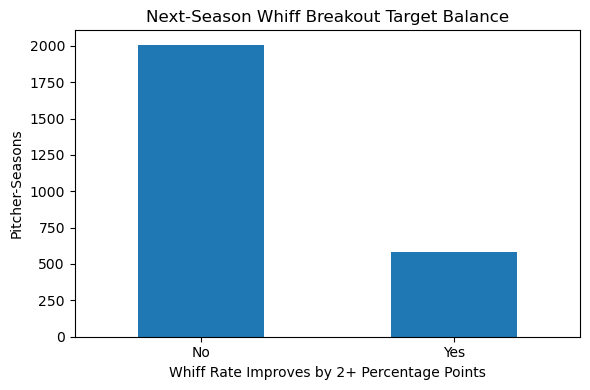

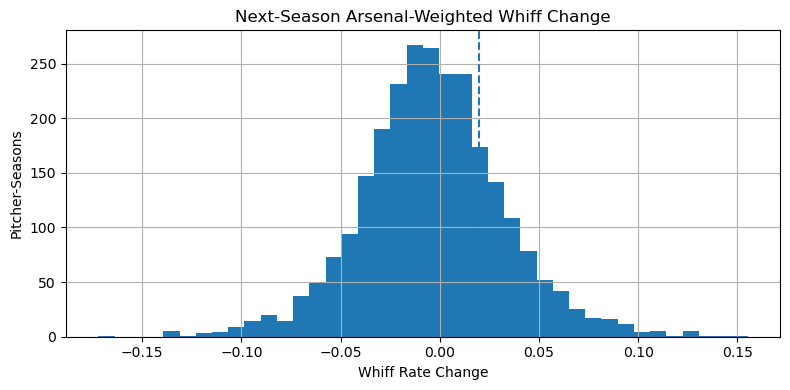

In [10]:
class_counts = labeled["whiff_breakout_next_year"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
class_counts.plot(kind="bar")
plt.title("Next-Season Whiff Breakout Target Balance")
plt.xlabel("Whiff Rate Improves by 2+ Percentage Points")
plt.ylabel("Pitcher-Seasons")
plt.xticks([0, 1], ["No", "Yes"], rotation=0)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
labeled["next_season_whiff_change"].hist(bins=40)
plt.axvline(BREAKOUT_THRESHOLD, linestyle="--")
plt.title("Next-Season Arsenal-Weighted Whiff Change")
plt.xlabel("Whiff Rate Change")
plt.ylabel("Pitcher-Seasons")
plt.tight_layout()
plt.show()


## 8. Year-over-year arsenal evolution features

The project is specifically about pitcher development, so the model should know whether an arsenal is already changing.

For every continuous arsenal measure, we calculate the change from the pitcher's previous season.

Examples:

- fastball velocity change,
- slider usage change,
- changeup whiff-rate change,
- overall weighted whiff change,
- pitch-mix changes,
- movement changes.

For a pitcher's first observed season, these deltas remain missing and are handled by the preprocessing pipeline.


In [11]:
DELTA_BASE_COLS = [
    c for c in pitchers.columns
    if any(
        c.endswith(suffix)
        for suffix in (
            "_usage_pct", "_avg_speed", "_avg_spin",
            "_whiff_rate", "_avg_pfx_x", "_avg_pfx_z"
        )
    )
]

DELTA_BASE_COLS += [
    "weighted_whiff_rate",
    "arsenal_size_5pct",
    "primary_pitch_usage",
    "usage_entropy",
    "weighted_velocity",
    "weighted_spin",
    "weighted_pfx_x",
    "weighted_pfx_z",
    "fastball_usage_pct",
    "breaking_usage_pct",
    "offspeed_usage_pct",
    "max_fastball_velocity",
    "max_secondary_velocity",
    "fastball_secondary_velo_gap",
    "weighted_whiff_dispersion",
]

DELTA_BASE_COLS = list(dict.fromkeys(DELTA_BASE_COLS))

for col in DELTA_BASE_COLS:
    pitchers[f"yoy_{col}"] = (
        pitchers.groupby("player_id")[col]
        .diff()
    )

print("Year-over-year features added:", len(DELTA_BASE_COLS))


Year-over-year features added: 123


## 9. Additional transparent development features

We add compact summaries that are easy to explain in a scouting or player-development context:

- share of pitches with above-arbitrary 20% whiff rate,
- highest individual pitch whiff rate,
- strongest secondary-pitch whiff rate,
- usage-weighted velocity,
- arsenal concentration.

These are derived only from season `t`.


In [12]:
pitch_whiff_matrix = pitchers[whiff_cols].to_numpy(dtype=float)
pitch_usage_matrix = pitchers[usage_cols].fillna(0.0).to_numpy(dtype=float) / 100.0

pitchers["max_pitch_whiff_rate"] = np.nanmax(pitch_whiff_matrix, axis=1)

secondary_whiff_cols = [
    f"{p}_whiff_rate" for p in PITCH_TYPES if p not in FASTBALLS
]
pitchers["max_secondary_whiff_rate"] = (
    pitchers[secondary_whiff_cols].max(axis=1, skipna=True)
)

pitchers["usage_on_20pct_plus_whiff_pitches"] = np.sum(
    np.where(
        np.nan_to_num(pitch_whiff_matrix, nan=-1) >= 0.20,
        pitch_usage_matrix,
        0.0,
    ),
    axis=1
)

display(
    pitchers[[
        "player_name", "season",
        "weighted_whiff_rate", "max_pitch_whiff_rate",
        "max_secondary_whiff_rate",
        "usage_on_20pct_plus_whiff_pitches"
    ]].head(12)
)


,player_name,season,weighted_whiff_rate,max_pitch_whiff_rate,max_secondary_whiff_rate,usage_on_20pct_plus_whiff_pitches
0,óliver pérez,2020,0.116559,0.1392,0.1392,0.0000
1,adam wainwright,2020,0.153429,0.2325,0.2325,0.3842
2,adam wainwright,2021,0.121046,0.3333,0.3333,0.0040
3,adam wainwright,2022,0.105825,0.1415,0.1415,0.0000
4,adam wainwright,2023,0.080369,0.1111,0.1050,0.0000
5,zack greinke,2020,0.162469,0.3918,0.3918,0.2217
6,zack greinke,2021,0.152395,0.2514,0.2514,0.3836
7,zack greinke,2022,0.114267,0.1810,0.1810,0.0000
8,zack greinke,2023,0.111592,0.1777,0.1777,0.0000
9,ervin santana,2021,0.180059,0.2601,0.2601,0.5165


## 10. Strict chronological split

A random split would mix future pitcher development into the training set.

We instead use:

| Set | Feature season | Outcome season |
|---|---:|---:|
| Train | 2020–2022 | 2021–2023 |
| Validation | 2023 | 2024 |
| Test | 2024 | 2025 |
| Forecast | 2025 | 2026 unknown |

Only pitchers with an observed following MLB season can enter train / validation / test.


In [13]:
model_df = pitchers.copy()

train_df = model_df[
    model_df["season"].between(2020, 2022)
    & model_df["whiff_breakout_next_year"].notna()
].copy()

val_df = model_df[
    model_df["season"].eq(2023)
    & model_df["whiff_breakout_next_year"].notna()
].copy()

test_df = model_df[
    model_df["season"].eq(2024)
    & model_df["whiff_breakout_next_year"].notna()
].copy()

forecast_2026_df = model_df[
    model_df["season"].eq(2025)
].copy()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)
print("2026 forecast population:", forecast_2026_df.shape)

print("\nBreakout rates:")
print("Train:", round(train_df["whiff_breakout_next_year"].mean(), 3))
print("Validation:", round(val_df["whiff_breakout_next_year"].mean(), 3))
print("Test:", round(test_df["whiff_breakout_next_year"].mean(), 3))


Train: (1540, 256)
Validation: (520, 256)
Test: (529, 256)
2026 forecast population: (738, 256)

Breakout rates:
Train: 0.224
Validation: 0.221
Test: 0.233


## 11. Final feature selection using training data only

We exclude:

- player ID and name,
- the future target and future whiff values,
- future change,
- season as a direct numeric trend shortcut.

Pitch-type and engineered arsenal variables are retained if they are not more than 90% missing in the training period and have more than one observed value.


In [14]:
EXACT_EXCLUDE = {
    "player_id",
    "player_name",
    "season",
    "next_season_weighted_whiff",
    "next_season_whiff_change",
    "whiff_breakout_next_year",
}

candidate_features = [
    c for c in model_df.columns
    if c not in EXACT_EXCLUDE
    and pd.api.types.is_numeric_dtype(model_df[c])
]

missing_rate = train_df[candidate_features].isna().mean()
nunique = train_df[candidate_features].nunique(dropna=True)

features = [
    c for c in candidate_features
    if missing_rate[c] <= 0.90
    and nunique[c] > 1
]

print("Candidate features:", len(candidate_features))
print("Final features:", len(features))

display(
    pd.DataFrame({
        "feature": features,
        "missing_rate_train": [missing_rate[c] for c in features],
    }).sort_values("missing_rate_train", ascending=False).head(30)
)


Candidate features: 250
Final features: 123


,feature,missing_rate_train
48,FS_avg_pfx_z,0.896753
4,FS_usage_pct,0.896753
22,FS_avg_spin,0.896753
39,FS_avg_pfx_x,0.896753
13,FS_avg_speed,0.896753
40,KC_avg_pfx_x,0.895455
14,KC_avg_speed,0.895455
5,KC_usage_pct,0.895455
49,KC_avg_pfx_z,0.895455
23,KC_avg_spin,0.895455


In [15]:
X_train = train_df[features]
y_train = train_df["whiff_breakout_next_year"].astype(int)

X_val = val_df[features]
y_val = val_df["whiff_breakout_next_year"].astype(int)

X_test = test_df[features]
y_test = test_df["whiff_breakout_next_year"].astype(int)

X_forecast = forecast_2026_df[features]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)


X_train: (1540, 123)
X_val: (520, 123)
X_test: (529, 123)


## 12. Preprocessing

All modeling variables are numeric.

Linear models receive median imputation and standardization. Tree models receive median imputation only.

Every transformation is fitted on the training period.


In [16]:
linear_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

tree_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])


## 13. Evaluation helpers

Probability quality matters for a player-development board because the output is used to rank pitchers, not merely assign a hard yes/no label.

Primary metrics:

- ROC-AUC,
- PR-AUC,
- log loss,
- Brier score.

Threshold-dependent metrics are reported at a selected operating point.


In [17]:
def probability_metrics(y_true, prob, threshold=0.50):
    prob = np.clip(np.asarray(prob, dtype=float), 1e-6, 1 - 1e-6)
    pred = (prob >= threshold).astype(int)

    return {
        "ROC_AUC": roc_auc_score(y_true, prob),
        "PR_AUC": average_precision_score(y_true, prob),
        "LogLoss": log_loss(y_true, prob),
        "Brier": brier_score_loss(y_true, prob),
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
    }

def print_probability_metrics(name, y_true, prob, threshold=0.50):
    m = probability_metrics(y_true, prob, threshold)
    print(name)
    for k, v in m.items():
        print(f"  {k}: {v:.4f}")
    return m


## 14. Baseline: historical breakout prevalence

The baseline gives every validation pitcher the same probability: the breakout rate observed in training.


In [18]:
base_rate = float(y_train.mean())
baseline_val_prob = np.full(len(y_val), base_rate)

baseline_metrics = print_probability_metrics(
    "Historical prevalence baseline",
    y_val,
    baseline_val_prob
)


Historical prevalence baseline
  ROC_AUC: 0.5000
  PR_AUC: 0.2212
  LogLoss: 0.5284
  Brier: 0.1723
  Accuracy: 0.7788
  Precision: 0.0000
  Recall: 0.0000
  F1: 0.0000


## 15. Logistic regression benchmark

Regularized logistic regression tests whether breakout probability can be explained with approximately linear relationships in the arsenal and year-over-year changes.


In [19]:
logit = Pipeline([
    ("prep", clone(linear_preprocessor)),
    ("model", LogisticRegression(
        C=0.20,
        penalty="l2",
        max_iter=5000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    )),
])

logit.fit(X_train, y_train)
logit_val_prob = logit.predict_proba(X_val)[:, 1]

logit_metrics = print_probability_metrics(
    "Logistic regression",
    y_val,
    logit_val_prob
)


Logistic regression
  ROC_AUC: 0.6738
  PR_AUC: 0.4168
  LogLoss: 0.6783
  Brier: 0.2368
  Accuracy: 0.6365
  Precision: 0.3333
  Recall: 0.6435
  F1: 0.4392


## 16. Random forest benchmark

The random forest can capture nonlinear development patterns and interactions across pitch mix, velocity, movement, and prior whiff performance.


In [20]:
rf = Pipeline([
    ("prep", clone(tree_preprocessor)),
    ("model", RandomForestClassifier(
        n_estimators=600,
        max_depth=10,
        min_samples_leaf=8,
        max_features=0.55,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])

rf.fit(X_train, y_train)
rf_val_prob = rf.predict_proba(X_val)[:, 1]

rf_metrics = print_probability_metrics(
    "Random forest",
    y_val,
    rf_val_prob
)


Random forest
  ROC_AUC: 0.7290
  PR_AUC: 0.4680
  LogLoss: 0.5022
  Brier: 0.1631
  Accuracy: 0.7673
  Precision: 0.4595
  Recall: 0.2957
  F1: 0.3598


## 17. Untuned XGBoost

Gradient boosting provides a strong nonlinear tabular benchmark before Bayesian tuning.


In [21]:
scale_pos_weight = (
    (y_train == 0).sum() / max((y_train == 1).sum(), 1)
)

xgb_base = Pipeline([
    ("prep", clone(tree_preprocessor)),
    ("model", XGBClassifier(
        n_estimators=500,
        learning_rate=0.035,
        max_depth=4,
        min_child_weight=7,
        subsample=0.85,
        colsample_bytree=0.70,
        reg_alpha=0.05,
        reg_lambda=2.0,
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=scale_pos_weight,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])

xgb_base.fit(X_train, y_train)
xgb_val_prob = xgb_base.predict_proba(X_val)[:, 1]

xgb_metrics = print_probability_metrics(
    "Untuned XGBoost",
    y_val,
    xgb_val_prob
)


Untuned XGBoost
  ROC_AUC: 0.6905
  PR_AUC: 0.4370
  LogLoss: 0.5279
  Brier: 0.1733
  Accuracy: 0.7500
  Precision: 0.4242
  Recall: 0.3652
  F1: 0.3925


## 18. Bayesian hyperparameter optimization with Optuna

We optimize XGBoost for validation **log loss**.

Log loss rewards accurate probabilities and heavily penalizes confident incorrect calls, which is appropriate for a ranked player-development board.


In [22]:
X_train_tree = tree_preprocessor.fit_transform(X_train)
X_val_tree = tree_preprocessor.transform(X_val)

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 900),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.12, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 7),
        "min_child_weight": trial.suggest_float("min_child_weight", 1.0, 20.0, log=True),
        "subsample": trial.suggest_float("subsample", 0.60, 1.00),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.45, 1.00),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 5.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        "scale_pos_weight": trial.suggest_float(
            "scale_pos_weight",
            max(1.0, scale_pos_weight * 0.5),
            max(1.1, scale_pos_weight * 1.5),
        ),
        "objective": "binary:logistic",
        "eval_metric": "logloss",
        "random_state": RANDOM_STATE,
        "n_jobs": -1,
    }

    model = XGBClassifier(**params)
    model.fit(X_train_tree, y_train)
    prob = model.predict_proba(X_val_tree)[:, 1]
    return log_loss(y_val, np.clip(prob, 1e-6, 1 - 1e-6))

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=N_TRIALS)

print("Best validation log loss:", round(study.best_value, 5))
display(pd.Series(study.best_params).to_frame("value"))


Best validation log loss: 0.49194


,value
n_estimators,792.000000
learning_rate,0.010053
max_depth,6.000000
min_child_weight,3.753023
subsample,0.725554
colsample_bytree,0.630074
reg_alpha,0.011880
reg_lambda,0.318891
scale_pos_weight,2.076429


In [23]:
best_xgb = XGBClassifier(
    **study.best_params,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

best_xgb.fit(X_train_tree, y_train)
tuned_val_prob = best_xgb.predict_proba(X_val_tree)[:, 1]

tuned_metrics = print_probability_metrics(
    "Optuna-tuned XGBoost",
    y_val,
    tuned_val_prob
)


Optuna-tuned XGBoost
  ROC_AUC: 0.6983
  PR_AUC: 0.4503
  LogLoss: 0.4919
  Brier: 0.1583
  Accuracy: 0.7808
  Precision: 0.5082
  Recall: 0.2696
  F1: 0.3523


## 19. Validation model comparison

The final model class is selected by validation log loss, with ROC-AUC and PR-AUC used as supporting diagnostics.


In [24]:
validation_predictions = {
    "Historical Prevalence": baseline_val_prob,
    "Logistic Regression": logit_val_prob,
    "Random Forest": rf_val_prob,
    "XGBoost": xgb_val_prob,
    "Tuned XGBoost": tuned_val_prob,
}

rows = []
for name, prob in validation_predictions.items():
    m = probability_metrics(y_val, prob)
    rows.append({"Model": name, **m})

comparison = (
    pd.DataFrame(rows)
    .sort_values("LogLoss")
    .reset_index(drop=True)
)

display(comparison)

best_model_name = comparison.iloc[0]["Model"]
print("Selected model:", best_model_name)


,Model,ROC_AUC,PR_AUC,LogLoss,Brier,Accuracy,Precision,Recall,F1
0,Tuned XGBoost,0.698250,0.450261,0.491945,0.158339,0.780769,0.508197,0.269565,0.352273
1,Random Forest,0.728975,0.467953,0.502232,0.163067,0.767308,0.459459,0.295652,0.359788
2,XGBoost,0.690499,0.436953,0.527947,0.173322,0.750000,0.424242,0.365217,0.392523
3,Historical Prevalence,0.500000,0.221154,0.528388,0.172253,0.778846,0.000000,0.000000,0.000000
4,Logistic Regression,0.673838,0.416813,0.678305,0.236781,0.636538,0.333333,0.643478,0.439169


Selected model: Tuned XGBoost


## 20. Choose a player-development decision threshold

A front office may prefer a shortlist with meaningful precision rather than labeling a large share of pitchers as breakouts.

We search validation thresholds and select the threshold with the best F1 score, breaking ties in favor of higher precision.


In [25]:
selected_val_prob = validation_predictions[best_model_name]

threshold_rows = []
for threshold in np.linspace(0.05, 0.90, 172):
    pred = (selected_val_prob >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_val, pred, zero_division=0),
        "recall": recall_score(y_val, pred, zero_division=0),
        "f1": f1_score(y_val, pred, zero_division=0),
        "positive_rate": pred.mean(),
    })

threshold_table = pd.DataFrame(threshold_rows)

best_threshold_row = (
    threshold_table.sort_values(
        ["f1", "precision", "threshold"],
        ascending=[False, False, True]
    )
    .iloc[0]
)

best_threshold = float(best_threshold_row["threshold"])

print("Selected threshold:", round(best_threshold, 3))
display(best_threshold_row.to_frame("value"))


Selected threshold: 0.239


,value
threshold,0.238889
precision,0.359447
recall,0.678261
f1,0.469880
positive_rate,0.417308


# 21. Final untouched test: predict 2025 breakouts from 2024 arsenals

After all model and threshold decisions are complete, we refit on 2020–2023 and evaluate once on 2024 → 2025.

This is the headline out-of-sample result.


In [26]:
train_val_df = pd.concat([train_df, val_df], ignore_index=True)

X_train_val = train_val_df[features]
y_train_val = train_val_df["whiff_breakout_next_year"].astype(int)

if best_model_name in {"Random Forest", "XGBoost", "Tuned XGBoost"}:
    final_preprocessor = clone(tree_preprocessor)
    X_train_val_t = final_preprocessor.fit_transform(X_train_val)
    X_test_t = final_preprocessor.transform(X_test)

    if best_model_name == "Random Forest":
        final_model = clone(rf.named_steps["model"])
    elif best_model_name == "XGBoost":
        final_model = clone(xgb_base.named_steps["model"])
    else:
        final_model = XGBClassifier(
            **study.best_params,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )

    final_model.fit(X_train_val_t, y_train_val)
    test_prob = final_model.predict_proba(X_test_t)[:, 1]

elif best_model_name == "Logistic Regression":
    final_preprocessor = clone(linear_preprocessor)
    X_train_val_t = final_preprocessor.fit_transform(X_train_val)
    X_test_t = final_preprocessor.transform(X_test)
    final_model = clone(logit.named_steps["model"])
    final_model.fit(X_train_val_t, y_train_val)
    test_prob = final_model.predict_proba(X_test_t)[:, 1]

else:
    final_preprocessor = None
    final_model = None
    test_prob = np.full(len(y_test), y_train_val.mean())

test_metrics = print_probability_metrics(
    "Untouched 2024 → 2025 test",
    y_test,
    test_prob,
    threshold=best_threshold
)


Untouched 2024 → 2025 test
  ROC_AUC: 0.6978
  PR_AUC: 0.4214
  LogLoss: 0.5144
  Brier: 0.1699
  Accuracy: 0.6257
  Precision: 0.3444
  Recall: 0.6748
  F1: 0.4560


## 22. Confusion matrix on the untouched test season


,Pred No Breakout,Pred Breakout
Actual No Breakout,248,158
Actual Breakout,40,83


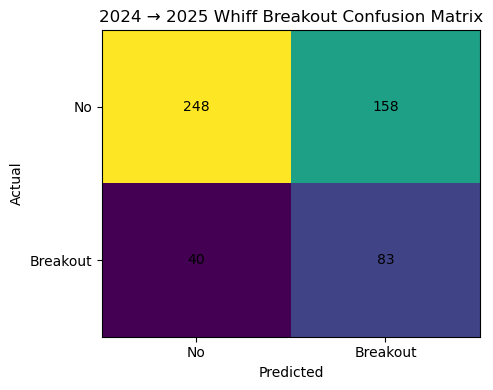

In [27]:
test_pred = (test_prob >= best_threshold).astype(int)
cm = confusion_matrix(y_test, test_pred)

cm_df = pd.DataFrame(
    cm,
    index=["Actual No Breakout", "Actual Breakout"],
    columns=["Pred No Breakout", "Pred Breakout"],
)

display(cm_df)

plt.figure(figsize=(5, 4))
plt.imshow(cm, aspect="auto")
plt.title("2024 → 2025 Whiff Breakout Confusion Matrix")
plt.xticks([0, 1], ["No", "Breakout"])
plt.yticks([0, 1], ["No", "Breakout"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout()
plt.show()


## 23. Probability calibration

A 40% breakout probability should correspond to roughly 40% observed breakouts among similarly scored pitchers.

Calibration is important because the deployment output is a probability-ranked development board.


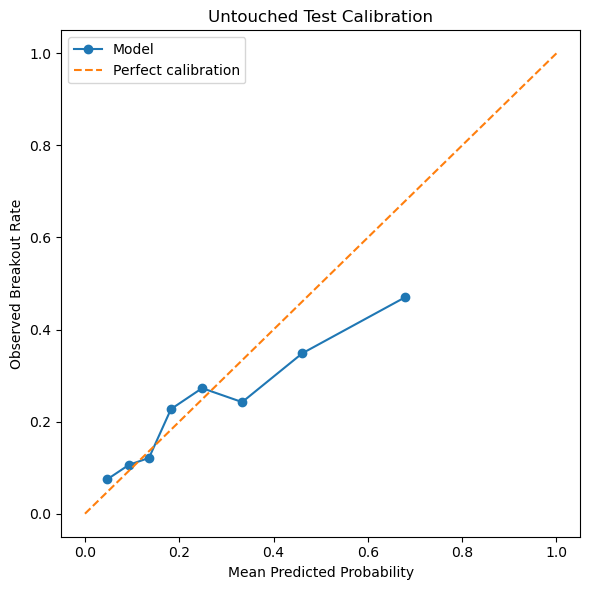

In [28]:
prob_true, prob_pred = calibration_curve(
    y_test,
    test_prob,
    n_bins=8,
    strategy="quantile"
)

plt.figure(figsize=(6, 6))
plt.plot(prob_pred, prob_true, marker="o", label="Model")
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Breakout Rate")
plt.title("Untouched Test Calibration")
plt.legend()
plt.tight_layout()
plt.show()


## 24. Build the test review table

The review table places the model probability next to actual year-over-year whiff change so false positives and false negatives can be examined as player-development cases.


In [29]:
test_output = test_df[[
    "player_id", "player_name", "season",
    "weighted_whiff_rate",
    "next_season_weighted_whiff",
    "next_season_whiff_change",
    "whiff_breakout_next_year",
    "arsenal_size_5pct",
    "weighted_velocity",
    "fastball_usage_pct",
    "breaking_usage_pct",
    "offspeed_usage_pct",
]].copy()

test_output["breakout_probability"] = test_prob
test_output["predicted_breakout"] = test_pred

display(
    test_output.sort_values("breakout_probability", ascending=False)
    .head(25)
)


,player_id,player_name,season,weighted_whiff_rate,next_season_weighted_whiff,next_season_whiff_change,whiff_breakout_next_year,arsenal_size_5pct,weighted_velocity,fastball_usage_pct,breaking_usage_pct,offspeed_usage_pct,breakout_probability,predicted_breakout
4113,690916,richard fitts,2024,0.105608,0.183914,0.078306,1.0,4,89.454808,43.48,43.75,12.77,0.942952,1
3273,669422,matt sauer,2024,0.115458,0.157190,0.041733,1.0,5,90.083065,54.13,39.76,6.12,0.910486,1
3168,668984,casey legumina,2024,0.076378,0.145285,0.068908,1.0,3,89.909864,50.00,23.49,26.51,0.882902,1
599,554431,tyler matzek,2024,0.098851,0.138373,0.039521,1.0,2,90.208648,67.60,32.40,0.00,0.880496,1
1672,622608,antonio senzatela,2024,0.096893,0.128468,0.031575,1.0,4,90.932496,58.72,29.36,11.93,0.863780,1
4229,800049,adam mazur,2024,0.118638,0.136779,0.018141,0.0,4,89.676645,43.32,46.40,10.27,0.833945,1
1236,606160,rafael montero,2024,0.132841,0.215588,0.082747,1.0,4,93.464104,69.21,7.91,22.88,0.818314,1
3501,672582,angel zerpa,2024,0.106280,0.106989,0.000709,0.0,4,92.868105,63.39,26.60,10.00,0.811116,1
1533,621199,matthew bowman,2024,0.124834,0.115995,-0.008839,0.0,4,88.175431,58.84,25.83,15.34,0.808606,1
4160,694361,will klein,2024,0.144987,0.173252,0.028265,1.0,3,92.688402,59.64,40.35,0.00,0.797536,1


## 25. Strongest correct calls


In [30]:
correct = test_output[
    test_output["predicted_breakout"].eq(
        test_output["whiff_breakout_next_year"].astype(int)
    )
].copy()

display(
    correct.assign(
        confidence=np.where(
            correct["predicted_breakout"].eq(1),
            correct["breakout_probability"],
            1 - correct["breakout_probability"],
        )
    )
    .sort_values("confidence", ascending=False)
    .head(20)
)


,player_id,player_name,season,weighted_whiff_rate,next_season_weighted_whiff,next_season_whiff_change,whiff_breakout_next_year,arsenal_size_5pct,weighted_velocity,fastball_usage_pct,breaking_usage_pct,offspeed_usage_pct,breakout_probability,predicted_breakout,confidence
3291,669456,shane bieber,2024,0.252248,0.188972,-0.063276,0.0,5,88.430603,51.21,35.54,13.25,0.016300,0,0.983700
774,592094,jason adam,2024,0.284730,0.237320,-0.047410,0.0,4,88.800907,38.51,35.78,25.71,0.016898,0,0.983102
3238,669276,dylan lee,2024,0.282346,0.246250,-0.036096,0.0,3,87.047847,33.30,54.85,11.86,0.019456,0,0.980544
82,453286,max scherzer,2024,0.213914,0.162375,-0.051539,0.0,5,86.659975,49.93,36.17,13.90,0.021469,0,0.978531
1061,600917,josé leclerc,2024,0.269227,0.270480,0.001253,0.0,5,89.473834,57.56,32.05,10.38,0.024197,0,0.975803
3189,669093,jeremiah estrada,2024,0.267640,0.256019,-0.011621,0.0,3,92.684531,55.74,24.32,19.95,0.025379,0,0.974621
1318,607455,anthony banda,2024,0.226048,0.206449,-0.019599,0.0,4,92.143776,57.40,31.46,11.15,0.028396,0,0.971604
837,592662,robbie ray,2024,0.263589,0.201871,-0.061718,0.0,3,90.676596,52.99,47.00,0.00,0.028633,0,0.971367
2116,643377,griffin jax,2024,0.270437,0.274361,0.003923,0.0,5,92.490895,39.54,43.88,16.59,0.029140,0,0.970860
1740,623474,jimmy herget,2024,0.205301,0.177733,-0.027567,0.0,5,84.941017,43.39,50.26,6.35,0.030241,0,0.969759


## 26. False positives and false negatives

These are often more informative than the aggregate metric because they show which arsenal changes the model misunderstood.


In [31]:
false_positives = test_output[
    (test_output["predicted_breakout"] == 1)
    & (test_output["whiff_breakout_next_year"] == 0)
].sort_values("breakout_probability", ascending=False)

false_negatives = test_output[
    (test_output["predicted_breakout"] == 0)
    & (test_output["whiff_breakout_next_year"] == 1)
].sort_values("breakout_probability")

print("False positives:")
display(false_positives.head(15))

print("False negatives:")
display(false_negatives.head(15))


False positives:


,player_id,player_name,season,weighted_whiff_rate,next_season_weighted_whiff,next_season_whiff_change,whiff_breakout_next_year,arsenal_size_5pct,weighted_velocity,fastball_usage_pct,breaking_usage_pct,offspeed_usage_pct,breakout_probability,predicted_breakout
4229,800049,adam mazur,2024,0.118638,0.136779,0.018141,0.0,4,89.676645,43.32,46.40,10.27,0.833945,1
3501,672582,angel zerpa,2024,0.106280,0.106989,0.000709,0.0,4,92.868105,63.39,26.60,10.00,0.811116,1
1533,621199,matthew bowman,2024,0.124834,0.115995,-0.008839,0.0,4,88.175431,58.84,25.83,15.34,0.808606,1
3875,681810,austin warren,2024,0.123125,0.103964,-0.019161,0.0,4,89.154267,60.70,39.31,0.00,0.772327,1
3978,685299,tanner gordon,2024,0.133565,0.131171,-0.002394,0.0,3,88.137293,49.75,31.14,19.11,0.762320,1
32,445926,jesse chavez,2024,0.106483,0.106538,0.000054,0.0,4,87.814742,78.08,8.59,13.34,0.737425,1
3552,674944,sean guenther,2024,0.113370,0.119277,0.005907,0.0,3,85.089535,43.54,26.19,30.27,0.734326,1
4132,691951,sam aldegheri,2024,0.136077,0.141194,0.005117,0.0,4,87.485613,56.76,22.07,21.17,0.720918,1
4223,702352,spencer bivens,2024,0.118786,0.118840,0.000054,0.0,5,90.029442,62.25,24.22,13.54,0.720511,1
3658,676661,max lazar,2024,0.134439,0.146836,0.012397,0.0,3,89.379082,74.43,25.57,0.00,0.706374,1


False negatives:


,player_id,player_name,season,weighted_whiff_rate,next_season_weighted_whiff,next_season_whiff_change,whiff_breakout_next_year,arsenal_size_5pct,weighted_velocity,fastball_usage_pct,breaking_usage_pct,offspeed_usage_pct,breakout_probability,predicted_breakout
4180,695243,mason miller,2024,0.295691,0.323356,0.027665,1.0,2,96.056068,63.16,34.91,1.93,0.017669,0
4111,690829,ben joyce,2024,0.211154,0.298086,0.086932,1.0,3,97.491957,80.96,15.16,3.88,0.038983,0
2840,664076,garrett cleavinger,2024,0.202994,0.236158,0.033164,1.0,5,90.163032,59.84,40.16,0.00,0.055911,0
2035,642232,ryan yarbrough,2024,0.149878,0.183711,0.033833,1.0,5,80.524447,57.39,27.43,15.18,0.058959,0
640,571578,patrick corbin,2024,0.167258,0.194840,0.027582,1.0,4,85.695966,60.53,36.18,3.29,0.069972,0
189,489446,kirby yates,2024,0.234599,0.269556,0.034956,1.0,2,90.434520,60.46,0.67,38.78,0.074604,0
3478,672282,reid detmers,2024,0.195633,0.216197,0.020564,1.0,4,87.893153,46.38,39.39,14.10,0.078925,0
2631,663321,nick hernandez,2024,0.203779,0.248166,0.044387,1.0,2,85.385528,37.41,58.27,4.32,0.094143,0
3886,681870,erik sabrowski,2024,0.201175,0.262438,0.061263,1.0,3,88.165970,53.42,46.58,0.00,0.094612,0
2444,657044,ryan thompson,2024,0.154710,0.174958,0.020248,1.0,3,88.031804,74.20,25.80,0.00,0.102682,0


## 27. Feature importance

For tree models we report model feature importance. For logistic regression we report absolute standardized coefficients.

This helps identify whether the breakout signal comes from:

- current whiff quality,
- pitch mix,
- velocity / spin,
- movement,
- or year-over-year arsenal changes.


,feature,importance
53,weighted_whiff_rate,0.021191
122,usage_on_20pct_plus_whiff_pitches,0.014525
105,yoy_weighted_whiff_rate,0.011891
65,max_fastball_velocity,0.010526
89,yoy_FC_whiff_rate,0.010184
101,yoy_FC_avg_pfx_z,0.010123
95,yoy_FC_avg_pfx_x,0.009977
82,yoy_CU_avg_spin,0.009869
30,FF_whiff_rate,0.009753
94,yoy_CU_avg_pfx_x,0.009675


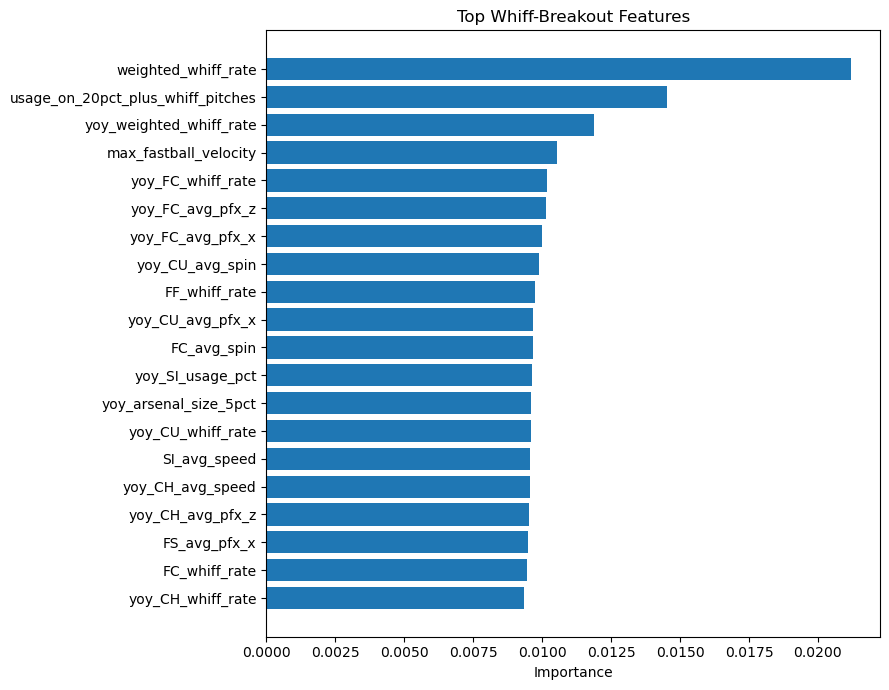

In [32]:
if best_model_name in {"Random Forest", "XGBoost", "Tuned XGBoost"}:
    importance = pd.DataFrame({
        "feature": features,
        "importance": final_model.feature_importances_,
    }).sort_values("importance", ascending=False)

elif best_model_name == "Logistic Regression":
    importance = pd.DataFrame({
        "feature": features,
        "importance": np.abs(final_model.coef_[0]),
    }).sort_values("importance", ascending=False)

else:
    importance = pd.DataFrame(columns=["feature", "importance"])

display(importance.head(30))

if len(importance):
    top_imp = importance.head(20).sort_values("importance")
    plt.figure(figsize=(9, 7))
    plt.barh(top_imp["feature"], top_imp["importance"])
    plt.title("Top Whiff-Breakout Features")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()


## 28. Inspect current-whiff vs improvement relationship

A breakout model may partly learn regression to the mean: pitchers starting from extremely high whiff rates have less room to improve.

This diagnostic makes that relationship explicit.


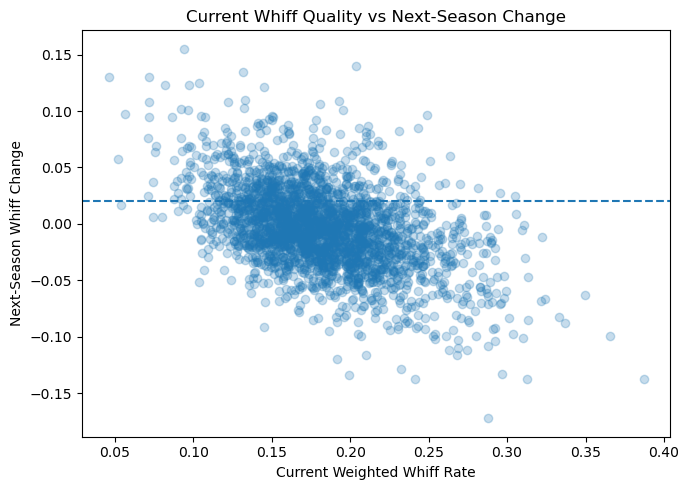

Correlation: -0.469


In [33]:
analysis_2020_2024 = pitchers[
    pitchers["next_season_whiff_change"].notna()
].copy()

plt.figure(figsize=(7, 5))
plt.scatter(
    analysis_2020_2024["weighted_whiff_rate"],
    analysis_2020_2024["next_season_whiff_change"],
    alpha=0.25,
)
plt.axhline(BREAKOUT_THRESHOLD, linestyle="--")
plt.xlabel("Current Weighted Whiff Rate")
plt.ylabel("Next-Season Whiff Change")
plt.title("Current Whiff Quality vs Next-Season Change")
plt.tight_layout()
plt.show()

print(
    "Correlation:",
    round(
        analysis_2020_2024[
            ["weighted_whiff_rate", "next_season_whiff_change"]
        ].corr().iloc[0, 1],
        3
    )
)


# 29. Train the deployment model and forecast 2026 breakout probabilities

The deployment model is fit on every labeled returner season from 2020–2024.

It then scores all 2025 pitchers.

The probabilities are conditional player-development signals, not predictions of whether the pitcher will remain in MLB.


In [34]:
all_labeled = model_df[
    model_df["whiff_breakout_next_year"].notna()
].copy()

X_all = all_labeled[features]
y_all = all_labeled["whiff_breakout_next_year"].astype(int)
X_2025 = forecast_2026_df[features]

if best_model_name in {"Random Forest", "XGBoost", "Tuned XGBoost"}:
    deployment_preprocessor = clone(tree_preprocessor)
    X_all_t = deployment_preprocessor.fit_transform(X_all)
    X_2025_t = deployment_preprocessor.transform(X_2025)

    if best_model_name == "Random Forest":
        deployment_model = clone(rf.named_steps["model"])
    elif best_model_name == "XGBoost":
        deployment_model = clone(xgb_base.named_steps["model"])
    else:
        deployment_model = XGBClassifier(
            **study.best_params,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )

    deployment_model.fit(X_all_t, y_all)
    forecast_prob = deployment_model.predict_proba(X_2025_t)[:, 1]

elif best_model_name == "Logistic Regression":
    deployment_preprocessor = clone(linear_preprocessor)
    X_all_t = deployment_preprocessor.fit_transform(X_all)
    X_2025_t = deployment_preprocessor.transform(X_2025)
    deployment_model = clone(logit.named_steps["model"])
    deployment_model.fit(X_all_t, y_all)
    forecast_prob = deployment_model.predict_proba(X_2025_t)[:, 1]

else:
    deployment_preprocessor = None
    deployment_model = None
    forecast_prob = np.full(len(forecast_2026_df), y_all.mean())


## 30. Build the 2026 pitcher-development board

The board combines model probability with current arsenal context.


In [35]:
board_cols = [
    "player_id", "player_name", "season",
    "weighted_whiff_rate",
    "arsenal_size_5pct",
    "primary_pitch_usage",
    "usage_entropy",
    "weighted_velocity",
    "weighted_spin",
    "fastball_usage_pct",
    "breaking_usage_pct",
    "offspeed_usage_pct",
    "fastball_secondary_velo_gap",
    "max_pitch_whiff_rate",
    "max_secondary_whiff_rate",
    "usage_on_20pct_plus_whiff_pitches",
    "yoy_weighted_whiff_rate",
    "yoy_weighted_velocity",
    "yoy_fastball_usage_pct",
    "yoy_breaking_usage_pct",
    "yoy_offspeed_usage_pct",
]

board_cols = [c for c in board_cols if c in forecast_2026_df.columns]

pitcher_board = forecast_2026_df[board_cols].copy()
pitcher_board["breakout_probability_2026"] = forecast_prob
pitcher_board["breakout_flag"] = (
    pitcher_board["breakout_probability_2026"] >= best_threshold
).astype(int)

pitcher_board = (
    pitcher_board.sort_values("breakout_probability_2026", ascending=False)
    .reset_index(drop=True)
)

display(pitcher_board.head(35))


,player_id,player_name,season,weighted_whiff_rate,arsenal_size_5pct,primary_pitch_usage,usage_entropy,weighted_velocity,weighted_spin,fastball_usage_pct,breaking_usage_pct,offspeed_usage_pct,fastball_secondary_velo_gap,max_pitch_whiff_rate,max_secondary_whiff_rate,usage_on_20pct_plus_whiff_pitches,yoy_weighted_whiff_rate,yoy_weighted_velocity,yoy_fastball_usage_pct,yoy_breaking_usage_pct,yoy_offspeed_usage_pct,breakout_probability_2026,breakout_flag
0,699911,dugan darnell,2025,0.094275,3,0.5255,1.014551,88.863120,1986.882000,52.55,19.90,27.55,9.12,0.1481,0.1481,0.0000,NaN,NaN,NaN,NaN,NaN,0.954544,1
1,673965,caleb freeman,2025,0.050819,3,0.5046,1.001721,90.483312,2547.867800,50.46,49.54,0.00,7.46,0.2222,0.2222,0.1560,NaN,NaN,NaN,NaN,NaN,0.923198,1
2,691251,andry lara,2025,0.084413,4,0.4627,1.175707,91.223240,2077.730973,61.56,32.55,5.88,6.36,0.3333,0.3333,0.0588,NaN,NaN,NaN,NaN,NaN,0.921700,1
3,700187,troy taylor,2025,0.108373,3,0.4706,1.059523,91.963492,2529.261600,61.03,37.50,1.47,5.88,0.2727,0.0909,0.1397,-0.082754,0.320748,3.24,-3.22,-0.03,0.897452,1
4,681799,ethan roberts,2025,0.096333,2,0.5764,0.832353,86.145158,2947.951000,42.36,57.64,0.00,10.78,0.1346,0.1346,0.0000,-0.071701,1.207962,1.64,-1.64,0.00,0.895864,1
5,678215,luarbert arias,2025,0.116615,4,0.4638,1.226033,86.824678,2118.305400,37.68,46.38,15.94,10.90,0.1667,0.1250,0.0000,NaN,NaN,NaN,NaN,NaN,0.881650,1
6,571771,enrique hernández,2025,0.079541,2,0.5520,0.822525,54.126240,1261.744000,4.00,40.80,0.00,30.32,0.1154,0.1154,0.0000,NaN,NaN,NaN,NaN,NaN,0.879256,1
7,669020,ryan rolison,2025,0.116797,3,0.4726,1.129623,87.051447,2442.416500,47.26,49.43,3.31,5.55,0.1497,0.1497,0.0000,NaN,NaN,NaN,NaN,NaN,0.878383,1
8,686747,joe la sorsa,2025,0.070570,4,0.4522,1.275336,88.071464,2078.393300,64.33,22.93,12.74,7.51,0.2273,0.2273,0.2293,0.016502,3.953273,5.28,3.37,-8.66,0.869701,1
9,702795,ryan loutos,2025,0.114090,5,0.4632,1.364008,91.643103,1958.074507,51.51,31.60,16.88,6.35,0.2059,0.2059,0.2251,NaN,NaN,NaN,NaN,NaN,0.861536,1


## 31. High-probability breakout candidates

For a more meaningful development shortlist, require at least three pitches used at 5%+ in 2025. This avoids ranking extremely narrow or unstable arsenals at the top solely because of sparse pitch-type information.


In [36]:
breakout_candidates = pitcher_board[
    pitcher_board["arsenal_size_5pct"] >= 3
].copy()

breakout_candidates = (
    breakout_candidates
    .sort_values("breakout_probability_2026", ascending=False)
    .head(30)
)

display(breakout_candidates)


,player_id,player_name,season,weighted_whiff_rate,arsenal_size_5pct,primary_pitch_usage,usage_entropy,weighted_velocity,weighted_spin,fastball_usage_pct,breaking_usage_pct,offspeed_usage_pct,fastball_secondary_velo_gap,max_pitch_whiff_rate,max_secondary_whiff_rate,usage_on_20pct_plus_whiff_pitches,yoy_weighted_whiff_rate,yoy_weighted_velocity,yoy_fastball_usage_pct,yoy_breaking_usage_pct,yoy_offspeed_usage_pct,breakout_probability_2026,breakout_flag
0,699911,dugan darnell,2025,0.094275,3,0.5255,1.014551,88.863120,1986.882000,52.55,19.90,27.55,9.12,0.1481,0.1481,0.0000,NaN,NaN,NaN,NaN,NaN,0.954544,1
1,673965,caleb freeman,2025,0.050819,3,0.5046,1.001721,90.483312,2547.867800,50.46,49.54,0.00,7.46,0.2222,0.2222,0.1560,NaN,NaN,NaN,NaN,NaN,0.923198,1
2,691251,andry lara,2025,0.084413,4,0.4627,1.175707,91.223240,2077.730973,61.56,32.55,5.88,6.36,0.3333,0.3333,0.0588,NaN,NaN,NaN,NaN,NaN,0.921700,1
3,700187,troy taylor,2025,0.108373,3,0.4706,1.059523,91.963492,2529.261600,61.03,37.50,1.47,5.88,0.2727,0.0909,0.1397,-0.082754,0.320748,3.24,-3.22,-0.03,0.897452,1
5,678215,luarbert arias,2025,0.116615,4,0.4638,1.226033,86.824678,2118.305400,37.68,46.38,15.94,10.90,0.1667,0.1250,0.0000,NaN,NaN,NaN,NaN,NaN,0.881650,1
7,669020,ryan rolison,2025,0.116797,3,0.4726,1.129623,87.051447,2442.416500,47.26,49.43,3.31,5.55,0.1497,0.1497,0.0000,NaN,NaN,NaN,NaN,NaN,0.878383,1
8,686747,joe la sorsa,2025,0.070570,4,0.4522,1.275336,88.071464,2078.393300,64.33,22.93,12.74,7.51,0.2273,0.2273,0.2293,0.016502,3.953273,5.28,3.37,-8.66,0.869701,1
9,702795,ryan loutos,2025,0.114090,5,0.4632,1.364008,91.643103,1958.074507,51.51,31.60,16.88,6.35,0.2059,0.2059,0.2251,NaN,NaN,NaN,NaN,NaN,0.861536,1
10,681151,jayden murray,2025,0.126175,4,0.4716,1.381524,92.580815,2412.653000,75.00,21.59,3.41,6.02,0.3043,0.3043,0.2216,NaN,NaN,NaN,NaN,NaN,0.853676,1
11,701121,logan vanwey,2025,0.113594,4,0.5177,1.257090,89.373124,2234.417700,64.60,24.34,11.06,6.75,0.1646,0.0882,0.0000,NaN,NaN,NaN,NaN,NaN,0.842698,1


## 32. Arsenal-change candidates

This second view highlights pitchers whose 2025 arsenal already changed materially.

It is useful for separating:

- a model prediction driven by established skill,
- from a prediction associated with recent velocity or pitch-mix evolution.


In [37]:
change_cols = [
    c for c in [
        "yoy_weighted_velocity",
        "yoy_fastball_usage_pct",
        "yoy_breaking_usage_pct",
        "yoy_offspeed_usage_pct",
        "yoy_weighted_whiff_rate",
    ]
    if c in pitcher_board.columns
]

if change_cols:
    change_view = pitcher_board[
        ["player_name", "breakout_probability_2026"] + change_cols
    ].copy()

    display(
        change_view.sort_values("breakout_probability_2026", ascending=False)
        .head(30)
    )


,player_name,breakout_probability_2026,yoy_weighted_velocity,yoy_fastball_usage_pct,yoy_breaking_usage_pct,yoy_offspeed_usage_pct,yoy_weighted_whiff_rate
0,dugan darnell,0.954544,NaN,NaN,NaN,NaN,NaN
1,caleb freeman,0.923198,NaN,NaN,NaN,NaN,NaN
2,andry lara,0.921700,NaN,NaN,NaN,NaN,NaN
3,troy taylor,0.897452,0.320748,3.24,-3.22,-0.03,-0.082754
4,ethan roberts,0.895864,1.207962,1.64,-1.64,0.00,-0.071701
5,luarbert arias,0.881650,NaN,NaN,NaN,NaN,NaN
6,enrique hernández,0.879256,NaN,NaN,NaN,NaN,NaN
7,ryan rolison,0.878383,NaN,NaN,NaN,NaN,NaN
8,joe la sorsa,0.869701,3.953273,5.28,3.37,-8.66,0.016502
9,ryan loutos,0.861536,NaN,NaN,NaN,NaN,NaN


## 33. Export the 2026 pitcher board


In [38]:
OUTPUT_PATH = Path("mlb_2026_pitcher_whiff_breakout_probabilities.csv")
pitcher_board.to_csv(OUTPUT_PATH, index=False)

print("Saved:", OUTPUT_PATH.resolve())
print("Rows:", len(pitcher_board))


Saved: /Users/svlahos/Downloads/mlb_2026_pitcher_whiff_breakout_probabilities.csv
Rows: 738


# 34. Baseball-operations interpretation

### What this model answers

For pitchers who remain active in MLB the following season, the model estimates the probability of a **meaningful improvement in arsenal-weighted whiff rate**.

That makes it useful as an exploratory tool for:

- player-development review,
- breakout candidate screening,
- pitch-design follow-up,
- scouting prioritization,
- identifying arsenal changes worth deeper video / biomechanical analysis.

### What it does not answer

The model does not directly predict:

- innings pitched,
- roster survival,
- injury,
- ERA,
- run prevention,
- command,
- contract value.

Whiff rate is only one component of pitcher quality.

### Important target limitation

Historical labels exist only for pitchers who appear in the next MLB season. Therefore, the model is estimating:

> **P(whiff breakout | pitcher appears next season)**

not the joint probability that a pitcher both returns and breaks out.

### Why the design is defensible

- Pitch usage is used to create a coherent overall arsenal whiff metric.
- Next-season labels are built with exact pitcher-season matching.
- Future seasons never enter current-season features.
- Year-over-year deltas use only prior seasons.
- Validation and test sets are strictly chronological.
- The 2024 → 2025 test is untouched until model and threshold selection are complete.
- Deployment scoring occurs only after evaluation.

### Portfolio takeaway

This project demonstrates:

- pitch-arsenal feature engineering,
- weighted player-performance metrics,
- longitudinal player-development analysis,
- leakage-safe year-over-year features,
- imbalanced classification,
- probability calibration,
- Bayesian hyperparameter optimization,
- chronological validation,
- error analysis,
- and a deployment-style pitcher-development board.
